In [1]:
%pip install requests beautifulsoup4 pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Mission 1 — Reconnaissance

Before writing the scraper, I inspected a product card on the Books to Scrape website to identify where the required information is stored.

1- **Book Title**:   `h3 a`  The full book title is stored in the `title` attribute 

2- **Price**:  `p.price_color` Contains the displayed price of the book 

3- **Rating**: `p.star-rating`  Rating is stored as a CSS class such as One, Two, Three, Four or Five 

4- **Availability**: `p.instock.availability`  Contains the stock availability information 

These HTML elements will be used by BeautifulSoup to extract the required book information.

## Mission 2: Capture the data

In [6]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

In [8]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=20)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Website connected successfully.")
print("Status code:", response.status_code)

Website connected successfully.
Status code: 200


In [10]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

In [12]:
first_page_books = []

for book in soup.select("article.product_pod"):

    title_element = book.select_one("h3 a")
    title = title_element["title"].strip()


    price_text = book.select_one("p.price_color").get_text(strip=True)
    price = float(
        price_text.replace("£", "").replace("Â", "").strip()
    )

    
    rating_classes = book.select_one("p.star-rating")["class"]

    rating_word = next(
        word for word in rating_classes
        if word in rating_map
    )

    rating = rating_map[rating_word]

    
    availability = book.select_one(
        "p.instock.availability"
    ).get_text(" ", strip=True)

    first_page_books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

first_page_df = pd.DataFrame(first_page_books)

print("Number of books scraped:", len(first_page_df))

display(first_page_df.head())

Number of books scraped: 20


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [14]:
print("Columns:")
print(first_page_df.columns.tolist())

print("\nMissing values:")
print(first_page_df.isnull().sum())

print("\nData types:")
print(first_page_df.dtypes)

print("\nRatings found:")
print(sorted(first_page_df["Rating"].unique()))

Columns:
['Title', 'Price', 'Rating', 'Availability']

Missing values:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Data types:
Title            object
Price           float64
Rating            int64
Availability     object
dtype: object

Ratings found:
[1, 2, 3, 4, 5]


## Mission 3 — Scale the operation

In [17]:
def scrape_books_page(page_url):
    """
    Scrapes book information from one catalogue page.
    Returns a list of dictionaries.
    """

    response = requests.get(page_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    books_data = []

    for book in soup.select("article.product_pod"):

        
        title_element = book.select_one("h3 a")
        title = title_element["title"].strip()

        
        price_text = book.select_one(
            "p.price_color"
        ).get_text(strip=True)

        price = float(
            price_text.replace("£", "")
            .replace("Â", "")
            .strip()
        )

        
        rating_classes = book.select_one(
            "p.star-rating"
        )["class"]

        rating_word = next(
            word for word in rating_classes
            if word in rating_map
        )

        rating = rating_map[rating_word]

        
        availability = book.select_one(
            "p.instock.availability"
        ).get_text(" ", strip=True)

        
        relative_url = title_element["href"]
        product_url = urljoin(page_url, relative_url)

        books_data.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Product_URL": product_url
        })

    return books_data

In [19]:
number_of_pages = 5

all_books = []

for page_number in range(1, number_of_pages + 1):

    if page_number == 1:
        page_url = "https://books.toscrape.com/"
    else:
        page_url = (
            f"https://books.toscrape.com/catalogue/"
            f"page-{page_number}.html"
        )

    page_books = scrape_books_page(page_url)

    all_books.extend(page_books)

    print(
        f"Page {page_number}: "
        f"{len(page_books)} books collected"
    )

Page 1: 20 books collected
Page 2: 20 books collected
Page 3: 20 books collected
Page 4: 20 books collected
Page 5: 20 books collected


In [21]:
books_df = pd.DataFrame(all_books)

print("Total books scraped:", len(books_df))

display(books_df.head())

Total books scraped: 100


,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [23]:

books_df["Title"] = books_df["Title"].str.strip()

books_df["Price"] = pd.to_numeric(
    books_df["Price"],
    errors="coerce"
)

books_df["Rating"] = pd.to_numeric(
    books_df["Rating"],
    errors="coerce"
)


books_df["Availability"] = (
    books_df["Availability"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


books_df = books_df.drop_duplicates(
    subset=["Title", "Product_URL"]
).reset_index(drop=True)

print("Dataset shape:", books_df.shape)

print("\nMissing values:")
print(books_df.isnull().sum())

print("\nData types:")
print(books_df.dtypes)

print("\nRating range:")
print(
    books_df["Rating"].min(),
    "to",
    books_df["Rating"].max()
)

Dataset shape: (100, 5)

Missing values:
Title           0
Price           0
Rating          0
Availability    0
Product_URL     0
dtype: int64

Data types:
Title            object
Price           float64
Rating            int64
Availability     object
Product_URL      object
dtype: object

Rating range:
1 to 5


In [25]:
books_df.to_csv(
    "competitor_books.csv",
    index=False,
    encoding="utf-8-sig"
)

print("competitor_books.csv saved successfully.")
print("Number of records:", len(books_df))

competitor_books.csv saved successfully.
Number of records: 100


In [27]:
check_df = pd.read_csv("competitor_books.csv")

print("CSV successfully read back.")
print("Rows:", len(check_df))
print("Columns:", check_df.columns.tolist())

display(check_df.head())

CSV successfully read back.
Rows: 100
Columns: ['Title', 'Price', 'Rating', 'Availability', 'Product_URL']


,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [29]:
import os

csv_path = os.path.abspath("competitor_books.csv")

print("CSV saved at:")
print(csv_path)

CSV saved at:
C:\Users\DELL\competitor_books.csv


## Boss Level — Scrape the Complete Catalogue

In [38]:
from urllib.parse import urljoin
import time

current_url = "https://books.toscrape.com/"

all_catalogue_books = []
visited_pages = set()

while current_url and current_url not in visited_pages:


    visited_pages.add(current_url)
    response = requests.get(current_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    page_books = scrape_books_page(current_url)

    all_catalogue_books.extend(page_books)

    print(
        f"Page {len(visited_pages)} scraped | "
        f"Books collected: {len(all_catalogue_books)}"
    )


    next_link = soup.select_one("li.next a")

    if next_link:
        current_url = urljoin(
            current_url,
            next_link["href"]
        )

    
        time.sleep(0.2)

    else:
        current_url = None



all_books_df = pd.DataFrame(all_catalogue_books)


all_books_df = all_books_df.drop_duplicates(
    subset=["Title", "Product_URL"]
).reset_index(drop=True)


all_books_df.to_csv(
    "competitor_books_all_pages.csv",
    index=False,
    encoding="utf-8-sig"
)


print("\nBoss Level Complete!")
print("Pages visited:", len(visited_pages))
print("Unique books collected:", len(all_books_df))

display(all_books_df.head())

Page 1 scraped | Books collected: 20
Page 2 scraped | Books collected: 40
Page 3 scraped | Books collected: 60
Page 4 scraped | Books collected: 80
Page 5 scraped | Books collected: 100
Page 6 scraped | Books collected: 120
Page 7 scraped | Books collected: 140
Page 8 scraped | Books collected: 160
Page 9 scraped | Books collected: 180
Page 10 scraped | Books collected: 200
Page 11 scraped | Books collected: 220
Page 12 scraped | Books collected: 240
Page 13 scraped | Books collected: 260
Page 14 scraped | Books collected: 280
Page 15 scraped | Books collected: 300
Page 16 scraped | Books collected: 320
Page 17 scraped | Books collected: 340
Page 18 scraped | Books collected: 360
Page 19 scraped | Books collected: 380
Page 20 scraped | Books collected: 400
Page 21 scraped | Books collected: 420
Page 22 scraped | Books collected: 440
Page 23 scraped | Books collected: 460
Page 24 scraped | Books collected: 480
Page 25 scraped | Books collected: 500
Page 26 scraped | Books collected: 520

,Title,Price,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


### Boss Level Result

The scraper was successfully extended to all catalogue pages using the same reusable function. This shows that the scraper can be scaled beyond the five-page dataset without repeating the extraction code.

## Mission 4 — Intelligence analysis

### 1. Which scraped book is the most expensive?

In [45]:
most_expensive = books_df.loc[
    books_df["Price"].idxmax()
]

print("Most Expensive Book:", most_expensive["Title"])
print(f"Price: £{most_expensive['Price']:.2f}")
print("Rating:", most_expensive["Rating"])

Most Expensive Book: The Death of Humanity: and the Case for Life
Price: £58.11
Rating: 4


### 2. Which scraped book is the cheapest?

In [50]:
cheapest = books_df.loc[
    books_df["Price"].idxmin()
]

print("Cheapest Book:", cheapest["Title"])
print(f"Price: £{cheapest['Price']:.2f}")
print("Rating:", cheapest["Rating"])

Cheapest Book: Patience
Price: £10.16
Rating: 3


### 3. What is the average book price?

In [53]:
average_price = books_df["Price"].mean()

print(f"Average Book Price: £{average_price:.2f}")

Average Book Price: £34.56


### 4. How many books have a 5-star rating?

In [56]:
five_star_books = books_df[
    books_df["Rating"] == 5
]

print("Number of 5-star books:", len(five_star_books))

Number of 5-star books: 19


### 5. What percentage of the scraped books are in stock?

In [59]:
in_stock_count = (
    books_df["Availability"]
    .str.contains("In stock", case=False, na=False)
    .sum()
)

in_stock_percentage = (
    in_stock_count / len(books_df)
) * 100

print(f"Books in stock: {in_stock_count}")
print(f"Percentage in stock: {in_stock_percentage:.2f}%")

Books in stock: 100
Percentage in stock: 100.00%


### 6. What are the Top 5 highest-rated books?

In [62]:
top_5_books = (
    books_df
    .sort_values(
        by=["Rating", "Price"],
        ascending=[False, True]
    )
    .head(5)
)

display(
    top_5_books[
        ["Title", "Price", "Rating", "Availability"]
    ]
)

,Title,Price,Rating,Availability
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5,In stock
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5,In stock
34,Sophie's World,15.94,5,In stock
54,Thirst,17.27,5,In stock
12,Set Me Free,17.46,5,In stock


### 7. Among the 5-star books, which one is the cheapest?

In [65]:
cheapest_five_star = five_star_books.loc[
    five_star_books["Price"].idxmin()
]

print(
    "Cheapest 5-star Book:",
    cheapest_five_star["Title"]
)

print(
    f"Price: £{cheapest_five_star['Price']:.2f}"
)

Cheapest 5-star Book: Princess Between Worlds (Wide-Awake Princess #5)
Price: £13.34


### Bonus Mission 3 — Books at Each Rating Level

To understand the competitor's rating distribution, I will count how many books in the scraped dataset belong to each star-rating level.

In [68]:
rating_counts = (
    books_df["Rating"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

rating_summary = pd.DataFrame({
    "Star Rating": rating_counts.index,
    "Number of Books": rating_counts.values
})

display(rating_summary)

,Star Rating,Number of Books
0,1,22
1,2,19
2,3,22
3,4,18
4,5,19


### Bonus Mission 4 — Rating Distribution Bar Chart

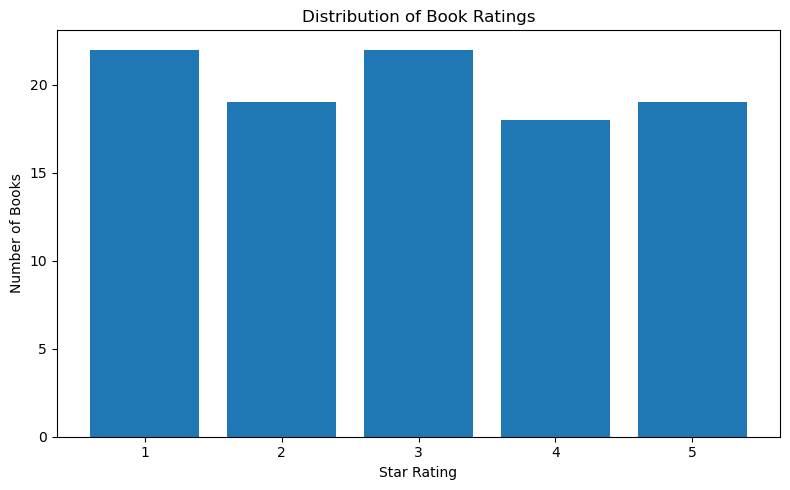

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    rating_summary["Star Rating"].astype(str),
    rating_summary["Number of Books"]
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

### Bonus Analysis Result

The rating distribution shows how the scraped books are spread across the five star-rating categories. The bar chart provides a simple visual comparison of these rating levels and helps identify which ratings are most common in the competitor's catalogue.

### Final Challenge — The CEO Has £100


In [75]:

ceo_books = books_df[
    ["Title", "Price", "Rating"]
].dropna().copy()

ceo_books = ceo_books[
    (ceo_books["Price"] > 0) &
    (ceo_books["Price"] <= 100) &
    (ceo_books["Rating"].between(1, 5))
].reset_index(drop=True)


ceo_books["Cost_Pence"] = (
    ceo_books["Price"] * 100
).round().astype(int)

budget = 10000   

print("Books available:", len(ceo_books))
print("Budget: £100")

Books available: 100
Budget: £100


In [77]:

best_rating = [0] * (budget + 1)


selected = [[] for _ in range(budget + 1)]

for index, book in ceo_books.iterrows():

    cost = int(book["Cost_Pence"])
    rating = int(book["Rating"])

    for current_budget in range(
        budget,
        cost - 1,
        -1
    ):

        new_rating = (
            best_rating[current_budget - cost]
            + rating
        )

        if new_rating > best_rating[current_budget]:

            best_rating[current_budget] = new_rating

            selected[current_budget] = (
                selected[current_budget - cost]
                + [index]
            )

print("Optimization complete.")

Optimization complete.


In [79]:
selected_indices = selected[budget]

selected_books = ceo_books.loc[
    selected_indices
].copy()

ceo_result = selected_books[
    ["Title", "Price", "Rating"]
].copy()

ceo_result["Price"] = ceo_result["Price"].round(2)

print("CEO £100 MARKET-RESEARCH CHALLENGE")

display(ceo_result)

CEO £100 MARKET-RESEARCH CHALLENGE


,Title,Price,Rating
12,Set Me Free,17.46,5
34,Sophie's World,15.94,5
47,Untitled Collection: Sabbath Poems 2014,14.27,4
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
84,Patience,10.16,3
92,Mama Tried: Traditional Italian Cooking for th...,14.02,4


In [81]:
total_cost_pence = selected_books["Cost_Pence"].sum()

total_cost = total_cost_pence / 100

total_rating = int(
    selected_books["Rating"].sum()
)

print(f"Total cost: £{total_cost:.2f}")

print(
    f"Budget remaining: "
    f"£{(budget - total_cost_pence) / 100:.2f}"
)

print(
    f"Total rating score: {total_rating}"
)

print(
    f"Number of books selected: "
    f"{len(selected_books)}"
)

Total cost: £98.80
Budget remaining: £1.20
Total rating score: 31
Number of books selected: 7


In [83]:
assert total_cost_pence <= budget, \
    "Budget exceeded!"

assert total_rating == best_rating[budget], \
    "Check the optimization result."

print("Budget constraint verified.")
print("Maximum rating score verified.")

Budget constraint verified.
Maximum rating score verified.


### Business Decision — Which Books Should We Prioritize?


In [86]:

priority_books = books_df[
    (books_df["Rating"] >= 4) &
    (books_df["Availability"].str.contains(
        "In stock", case=False, na=False
    ))
].copy()


priority_books = priority_books.sort_values(
    by=["Rating", "Price"],
    ascending=[False, True]
)

print("BUSINESS DECISION ANALYSIS")
print("--------------------------")

print(
    "Number of in-stock books rated 4 or 5:",
    len(priority_books)
)

print(
    f"Average price of these books: "
    f"£{priority_books['Price'].mean():.2f}"
)

print(
    f"Overall average book price: "
    f"£{books_df['Price'].mean():.2f}"
)

print(
    f"Overall average rating: "
    f"{books_df['Rating'].mean():.2f} stars"
)

BUSINESS DECISION ANALYSIS
--------------------------
Number of in-stock books rated 4 or 5: 37
Average price of these books: £31.94
Overall average book price: £34.56
Overall average rating: 2.93 stars


In [88]:
print("Top 5 Books to Prioritize")

display(
    priority_books[
        ["Title", "Price", "Rating", "Availability"]
    ].head(5)
)

Top 5 Books to Prioritize


,Title,Price,Rating,Availability
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5,In stock
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5,In stock
34,Sophie's World,15.94,5,In stock
54,Thirst,17.27,5,In stock
12,Set Me Free,17.46,5,In stock


### Recommendation

I would prioritize the highly rated books that are currently in stock, particularly the five candidates shown above. There are **[NUMBER] in-stock books rated 4 or 5 stars**, and their average price is **£[AVERAGE]**, compared with an overall average book price of **£[OVERALL AVERAGE]**. These results suggest that highly rated books with competitive prices would be strong products to prioritize in a competing bookstore.